# Unit 4 · Natural Language & Conversational Visualization — Case-Based Activity
**Case:** *Auditing ChatViz at RideNow*

RideNow is a ride-hailing company. Its operations team has piloted **ChatViz**, a chat assistant that turns plain-language questions into charts and lets analysts keep refining them in conversation.
Before it goes to every analyst, you have been asked to **audit** it: how it reads a question, how it handles follow-ups, how it generates and validates chart specifications, how it edits charts, and what goes wrong.

**How to work**
* Run the cells from top to bottom. Do **not** edit the setup cell.
* Wherever you see `# TODO`, replace the placeholder (`None` or `""`) with your answer or code.
* Written answers: two or three sentences, using ideas from the lecture.

In [ ]:
import math, re, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")
plt.rcParams.update({"figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False, "axes.titlesize": 10, "axes.titleweight": "bold"})
pd.set_option("display.max_columns", 20, "display.width", 140, "display.max_colwidth", 90)

In [ ]:
# ---------------- mini Vega-Lite-style renderer (do not edit) ----------------
import copy, json, difflib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

MONTHS = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
ACCENT, GREY, BLUE = "#E8710A", "#BDBDBD", "#4C72B0"

def apply_filters(df, spec):
    for t in spec.get("transform", []):
        f = t.get("filter")
        if not f:
            continue
        if "equal" in f:
            df = df[df[f["field"]] == f["equal"]]
        elif "oneOf" in f:
            df = df[df[f["field"]].isin(f["oneOf"])]
    return df

def is_horizontal(spec):
    e = spec["encoding"]
    return spec["mark"] == "bar" and e["x"].get("type") == "quantitative" and e["y"].get("type") in ("nominal", "ordinal")

def compute(spec, df):
    """Return the tidy table that the chart plots (used for drawing AND for checking values)."""
    enc, mark = spec["encoding"], spec["mark"]
    d = apply_filters(df, spec)
    x, y, c = enc["x"], enc["y"], enc.get("color", {})
    sf = c.get("field")
    if mark == "point":
        return d[[x["field"], y["field"]] + ([sf] if sf else [])].copy()
    if x.get("bin"):
        return d[[x["field"]]].copy()
    cat, val = (y, x) if is_horizontal(spec) else (x, y)
    agg = val.get("aggregate", "mean")
    keys = [cat["field"]] + ([sf] if sf else [])
    out = d.groupby(keys).size().rename("value") if agg == "count" else d.groupby(keys)[val["field"]].agg(agg).rename("value")
    return out.reset_index()

def _order(labels, field, sort, totals):
    labels = list(dict.fromkeys(labels))
    if sort in ("-y", "-x"):
        return sorted(labels, key=lambda l: -totals[l])
    if sort in ("y", "x"):
        return sorted(labels, key=lambda l: totals[l])
    if field == "month":
        return sorted(labels, key=MONTHS.index)
    return sorted(labels)

def render_spec(spec, df, ax=None, figsize=(6, 3.4)):
    enc, mark = spec["encoding"], spec["mark"]
    if ax is None:
        _, ax = plt.subplots(figsize=figsize)
    t = compute(spec, df)
    x, y, c = enc["x"], enc["y"], enc.get("color", {})
    sf = c.get("field")
    if mark == "point":
        if sf:
            for k, g in t.groupby(sf):
                ax.scatter(g[x["field"]], g[y["field"]], s=10, alpha=.6, label=str(k))
            ax.legend(fontsize=7, title=sf, title_fontsize=7)
        else:
            ax.scatter(t[x["field"]], t[y["field"]], s=10, alpha=.5, color=BLUE)
        ax.set_xlabel(x.get("title", x["field"])); ax.set_ylabel(y.get("title", y["field"]))
    elif x.get("bin"):
        ax.hist(t[x["field"]], bins=25, color=BLUE)
        ax.set_xlabel(x.get("title", x["field"])); ax.set_ylabel(y.get("title", "count"))
    else:
        horiz = is_horizontal(spec)
        cat, val = (y, x) if horiz else (x, y)
        cf = cat["field"]
        tot = t.groupby(cf)["value"].sum()
        labels = _order(t[cf], cf, cat.get("sort"), tot)
        idx = np.arange(len(labels))
        series = sorted(t[sf].unique()) if sf else [None]
        for j, s in enumerate(series):
            g = t if s is None else t[t[sf] == s]
            vals = g.set_index(cf)["value"].reindex(labels).values
            if mark == "bar":
                w = 0.8 / len(series)
                pos = idx + (j - (len(series) - 1) / 2) * w
                colors = BLUE
                cond = c.get("condition")
                if s is None and cond:
                    colors = [ACCENT if l == cond["equal"] else c.get("value", GREY) for l in labels]
                (ax.barh if horiz else ax.bar)(pos, vals, w * 0.95, color=colors, label=None if s is None else str(s))
            else:
                ax.plot(idx, vals, marker="o", ms=3, label=None if s is None else str(s))
        (ax.set_yticks if horiz else ax.set_xticks)(idx)
        (ax.set_yticklabels if horiz else ax.set_xticklabels)(labels, fontsize=8)
        if horiz: ax.invert_yaxis()
        vtitle = val.get("title") or f"{val.get('aggregate', 'mean')}({val['field']})"
        ctitle = cat.get("title") or cat["field"]
        (ax.set_ylabel if not horiz else ax.set_xlabel)(vtitle)
        (ax.set_xlabel if not horiz else ax.set_ylabel)(ctitle)
        sc = val.get("scale", {})
        if sc.get("type") == "log":
            (ax.set_xscale if horiz else ax.set_yscale)("log")
        if mark == "bar" and sc.get("zero") is False:
            lo = t["value"].min() * 0.96
            (ax.set_xlim if horiz else ax.set_ylim)(lo, t["value"].max() * 1.02)
        if sf:
            ax.legend(fontsize=7, title=sf, title_fontsize=7)
    ax.set_title(spec.get("title", ""), fontsize=10, fontweight="bold", loc="left")
    return ax

def show_specs(specs, df, ncols=3, w=4.6, h=3.3):
    n = len(specs); nrows = -(-n // ncols)
    fig, axes = plt.subplots(nrows, ncols, figsize=(w * ncols, h * nrows), squeeze=False)
    for ax in axes.ravel(): ax.axis("off")
    for ax, s in zip(axes.ravel(), specs):
        ax.axis("on"); render_spec(s, df, ax=ax)
    plt.tight_layout(); plt.show()

In [ ]:
# ---------------- synthetic RideNow trips (do not edit) ----------------
rng = np.random.default_rng(21)
n = 1200
city = rng.choice(["Bengaluru", "Hyderabad", "Chennai", "Pune"], n, p=[.38, .27, .20, .15])
vehicle = rng.choice(["Auto", "Mini", "Sedan", "Bike"], n, p=[.30, .35, .20, .15])
year = rng.choice([2024, 2025], n)
month = rng.choice(MONTHS, n)
distance = np.clip(rng.gamma(2.4, 2.6, n), 0.8, 30).round(1)
mult = {"Auto": 9, "Mini": 11, "Sedan": 14, "Bike": 6}
city_f = {"Bengaluru": 1.10, "Hyderabad": 1.00, "Chennai": 0.95, "Pune": 1.05}
fare = (35 + distance * np.array([mult[v] for v in vehicle]) * np.array([city_f[c] for c in city]) * rng.normal(1, .06, n)).round(0)
wait = np.clip(rng.gamma(2.2, 2.0, n) + (city == "Bengaluru") * 2.5, 0.5, None).round(1)
cancel_p = np.clip(0.03 + 0.004 * wait + (city == "Chennai") * 0.012 - (city == "Pune") * 0.01, 0.005, None)

df = pd.DataFrame({
    "city": city, "year": year, "month": month, "vehicle_type": vehicle, "distance_km": distance, "fare": fare, "wait_min": wait,
    "driver_rating": np.clip(rng.normal(4.4, .35, n) - 0.02 * wait, 1, 5).round(1),
    "payment_mode": rng.choice(["UPI", "Cash", "Card", "Wallet"], n, p=[.55, .20, .15, .10]),
    "cancelled": (rng.random(n) < cancel_p).astype(int),
})

# helpers used later (do not edit)
def spec_diff(a, b):
    def flat(d, p=""):
        out = {}
        for k, v in d.items():
            q = f"{p}.{k}" if p else k
            out.update(flat(v, q) if isinstance(v, dict) else {q: str(v)})
        return out
    fa, fb = flat(a), flat(b)
    return sorted(k for k in set(fa) | set(fb) if fa.get(k) != fb.get(k))

def lint_chart(spec):
    issues, t = [], spec.get("title", "").strip().lower()
    if not t: issues.append("no title")
    if re.match(r"^(this|the) (chart|figure|graph|plot) (shows|displays|presents)", t): issues.append("title describes the chart instead of asserting the point")
    for ch in ("x", "y"):
        e = spec["encoding"].get(ch, {})
        if e.get("type") == "quantitative" and "title" not in e: issues.append(f"{ch}-axis has no title with units")
    return issues or ["OK"]

df.head()

,city,year,month,vehicle_type,distance_km,fare,wait_min,driver_rating,payment_mode,cancelled
0,Chennai,2025,Sep,Bike,4.8,59.0,2.3,5.0,UPI,0
1,Hyderabad,2024,Aug,Auto,9.9,122.0,4.7,4.5,Card,0
2,Chennai,2025,Aug,Mini,3.1,65.0,8.1,4.0,UPI,0
3,Bengaluru,2024,Sep,Mini,2.6,64.0,6.5,4.8,UPI,0
4,Hyderabad,2024,Sep,Mini,3.5,77.0,3.0,4.7,Cash,0


---
## Case 1 · How does ChatViz *read* a question? (NL2Vis, query → task abstraction, semantic parsing, ambiguity)
### 1a · From words to abstract tasks
Seven questions came in on the first day. For each one, name the **abstract task** ChatViz should infer.
Use exactly one of: `"trend"`, `"compare"`, `"extremes"`, `"distribution"`, `"correlation"`, `"part-to-whole"`, `"outliers"`.

In [ ]:
questions = {
    "Q1": "How did the number of rides change month by month in 2025?",
    "Q2": "Compare average fare across cities",
    "Q3": "Does fare depend on distance?",
    "Q4": "Which 2 cities had the highest cancellation rate?",
    "Q5": "How spread out are the driver ratings?",
    "Q6": "What percentage of rides are paid by UPI?",
    "Q7": "Compare auto and sedan fares over the last 2 years",
}
TASKS = ["trend", "compare", "extremes", "distribution", "correlation", "part-to-whole", "outliers"]
DEFAULT_CHART = {"trend": "line chart", "compare": "sorted bar chart", "extremes": "sorted bar, top-k highlighted", "distribution": "histogram / boxplot",
                 "correlation": "scatter plot", "part-to-whole": "stacked bar (few parts)", "outliers": "scatter / line with highlights"}
pd.Series(questions, name="question").to_frame()

,question
Q1,How did the number of rides change month by month in 2025?
Q2,Compare average fare across cities
Q3,Does fare depend on distance?
Q4,Which 2 cities had the highest cancellation rate?
Q5,How spread out are the driver ratings?
Q6,What percentage of rides are paid by UPI?
Q7,Compare auto and sedan fares over the last 2 years


In [ ]:
abstract_tasks = {
    "Q1": "trend",
    "Q2": "compare",
    "Q3": "correlation",
    "Q4": "extremes",
    "Q5": "distribution",
    "Q6": "part-to-whole",
    "Q7": "compare",
}
assert all(v in TASKS for v in abstract_tasks.values()), "Choose each answer from TASKS"
pd.DataFrame({"question": questions, "your task": abstract_tasks}).assign(chart=lambda d: d["your task"].map(DEFAULT_CHART))

,question,your task,chart
Q1,How did the number of rides change month by month in 2025?,trend,line chart
Q2,Compare average fare across cities,compare,sorted bar chart
Q3,Does fare depend on distance?,correlation,scatter plot
Q4,Which 2 cities had the highest cancellation rate?,extremes,"sorted bar, top-k highlighted"
Q5,How spread out are the driver ratings?,distribution,histogram / boxplot
Q6,What percentage of rides are paid by UPI?,part-to-whole,stacked bar (few parts)
Q7,Compare auto and sedan fares over the last 2 years,compare,sorted bar chart


### 1b · Typos in attribute names
A user typed *"show avg **distnce** by city"*. ChatViz matches a word to a column using **similarity = 1 − d / max(len(a), len(b))**, where *d* is the Levenshtein distance,
and accepts the best match only if it is **≥ 0.7**; otherwise it must **ask, not guess**. The Levenshtein function is given; write `similarity` and `match_column`.

In [ ]:
def levenshtein(a, b):
    prev = list(range(len(b) + 1))
    for i, ca in enumerate(a, 1):
        cur = [i]
        for j, cb in enumerate(b, 1):
            cur.append(min(prev[j] + 1, cur[j - 1] + 1, prev[j - 1] + (ca != cb)))
        prev = cur
    return prev[-1]

known_columns = ["distance", "duration", "discount", "driver", "fare"]

In [ ]:
known_columns = ["distance", "duration", "discount", "driver", "fare"]

def levenshtein(a, b):
    prev = list(range(len(b) + 1))
    for i, ca in enumerate(a, 1):
        cur = [i]
        for j, cb in enumerate(b, 1):
            cur.append(min(prev[j] + 1, cur[j - 1] + 1, prev[j - 1] + (ca != cb)))
        prev = cur
    return prev[-1]

def similarity(a, b):
    d = levenshtein(a, b)
    denom = max(len(a), len(b))
    if denom == 0:
        return 1.0
    return 1 - d / denom

def match_column(token, columns, threshold=0.7):
    best_col = None
    best_sim = -1
    for col in columns:
        sim = similarity(token, col)
        if sim > best_sim:
            best_sim = sim
            best_col = col
    if best_sim >= threshold:
        return best_col
    return None

for tok in ["distnce", "fre", "zzzz"]:
    print(f"{tok!r:10} -> {match_column(tok, known_columns)}")

assert match_column("distnce", known_columns) == "distance"
assert match_column("fre", known_columns) == "fare"
assert match_column("zzzz", known_columns) is None, "no column passes the threshold: ask the user"

'distnce'  -> distance
'fre'      -> fare
'zzzz'     -> None


### 1c · Handling ambiguity
ChatViz can resolve an ambiguous query in three ways: `"default + show interpretation"`, `"ambiguity widget"`, or `"clarifying question"`.
Pick the **best-fitting** strategy for each situation.

* **S1.** An analyst is exploring casually and types *"show fare"*. The table has `base_fare` and `total_fare`. A wrong guess costs nothing and she wants speed.
* **S2.** A manager types *"top rides"* and three things are unclear at once: **top by what** (fare / distance), **sum or average**, and **which year**. He can see the screen.
* **S3.** A chart for a regulator's filing is requested: *"average fare"*, and there is exactly **one** doubt: `fare` vs `fare_after_discount`. A wrong guess here is costly.

### Reflection: interpreting natural-language requests

Answer each question in two or three sentences, using ideas from the lecture and evidence from your work.

1. Which words or phrases in a user's question are most important for identifying the intended measure, dimensions, filters, and chart type? Explain why.

   Nouns and continuous columns (such as fare or distance) are critical for identifying the intended quantitative measures, while categorical terms (like city or vehicle) point to the dimensions or groupings. Prepositions and comparison terms (such as by, over, during 2025) are essential for parsing grouping variables and filters, whereas verbs/action phrases (compare, does depend on) help select the correct abstract task and matching chart type.

2. How should ChatViz respond when a user's request is ambiguous in more than one way? Give an example of a useful clarifying question.

   When faced with multi-criteria ambiguity, ChatViz should avoid asking multiple disjoint questions and instead offer a structured ambiguity widget on screen or ask a single, targeted clarifying question. For example, it could ask: Should I show the average fare or total fare, and do you want to filter the results only for 2025?

3. How could different analysts interpret the same natural-language request differently? What design choices could make ChatViz's behavior more consistent?

   Different analysts might bring different domain-level assumptions, such as defining revenue as gross fare receipts versus net earnings after driver cuts, or expecting different sorting behaviors on a bar chart. To make behavior consistent, ChatViz should always explicitly echo its parsed interpretation (like Showing average fare by city for 2025) and make the visual mappings and filter rules fully transparent and editable.

In [ ]:
ambiguity_strategy = {
    "S1": "default + show interpretation",
    "S2": "ambiguity widget",
    "S3": "clarifying question",
}
STRATEGIES = {"default + show interpretation", "ambiguity widget", "clarifying question"}
assert all(v in STRATEGIES for v in ambiguity_strategy.values()), "Use one of the three strategy names"

---
## Case 2 · Conversations (conversational systems, multi-turn refinement, follow-ups and context)
ChatViz keeps a **dialogue state**: the measure, aggregation, x field, colour field, filters and mark.
### 2a · Name the turn
For each utterance (said *after* a chart of mean fare by city), name the **turn type**, choosing from `TURN_TYPES`.
Then, for three follow-ups said after *"fares in Chennai in 2025"*, name the **context transition**: `"Continue"`, `"Retain"` or `"Shift"`.

In [ ]:
TURN_TYPES = ["Refine (filter)", "Elaborate (add field)", "Change aggregation", "Change view", "Drill down", "Compare", "Shift / reset"]
utterances = {
    "U1": "only for Bengaluru and Pune",
    "U2": "split it by vehicle type",
    "U3": "show the median instead",
    "U4": "as a line chart",
    "U5": "and how does that compare with 2024?",
    "U6": "now show driver ratings by city",
}
follow_ups = {
    "T1": "by vehicle type",
    "T2": "what about wait times?",
    "T3": "show cancellations by city",
}
display(pd.Series(utterances, name="utterance").to_frame()); display(pd.Series(follow_ups, name="follow-up").to_frame())

,utterance
U1,only for Bengaluru and Pune
U2,split it by vehicle type
U3,show the median instead
U4,as a line chart
U5,and how does that compare with 2024?
U6,now show driver ratings by city


,follow-up
T1,by vehicle type
T2,what about wait times?
T3,show cancellations by city


In [ ]:
TURN_TYPES = ["Refine (filter)", "Elaborate (add field)", "Change aggregation", "Change view", "Drill down", "Compare", "Shift / reset"]

turn_types = {
    "U1": "Refine (filter)",
    "U2": "Elaborate (add field)",
    "U3": "Change aggregation",
    "U4": "Change view",
    "U5": "Compare",
    "U6": "Shift / reset",
}
transitions = {
    "T1": "Continue",
    "T2": "Retain",
    "T3": "Shift",
}
assert all(v in TURN_TYPES for v in turn_types.values()), "Choose from TURN_TYPES"
assert all(v in {"Continue", "Retain", "Shift"} for v in transitions.values()), "Use Continue, Retain or Shift"

### 2b · Update the dialogue state
Complete `apply_turn(state, turn, **kw)`. It must return a **new** state (never modify the old one) and only change the slot that the turn affects:

| `turn` | keyword | change |
|---|---|---|
| `"refine"` | `field`, `values` | set `filters[field] = values` |
| `"elaborate"` | `field` | `color = field` |
| `"change_agg"` | `agg` | `agg = agg` |
| `"change_view"` | `mark` | `mark = mark` |
| `"shift"` | `new_state` | return `new_state` (everything old is dropped) |

In [ ]:
import copy

def apply_turn(state, turn, **kw):
    new = copy.deepcopy(state)
    if turn == "refine":
        new["filters"][kw["field"]] = kw["values"]
    elif turn == "elaborate":
        new["color"] = kw["field"]
    elif turn == "change_agg":
        new["agg"] = kw["agg"]
    elif turn == "change_view":
        new["mark"] = kw["mark"]
    elif turn == "shift":
        new = copy.deepcopy(kw["new_state"])
    return new

s0 = {"measure": "fare", "agg": "mean", "x": "city", "color": None, "filters": {}, "mark": "bar"}
s1 = apply_turn(s0, "refine", field="year", values=[2025])
s2 = apply_turn(s1, "refine", field="city", values=["Chennai", "Pune"])
s3 = apply_turn(s2, "elaborate", field="vehicle_type")
s4 = apply_turn(s3, "change_agg", agg="median")
s5 = apply_turn(s4, "change_view", mark="line")
s6 = apply_turn(s5, "shift", new_state={"measure": "driver_rating", "agg": "mean", "x": "city", "color": None, "filters": {}, "mark": "bar"})
for i, s in enumerate([s0, s1, s2, s3, s4, s5, s6]): print(i, s)

assert s0["filters"] == {}, "apply_turn must not modify the old state"
assert s2["filters"] == {"year": [2025], "city": ["Chennai", "Pune"]}, "earlier filters must be inherited"
assert s5["agg"] == "median" and s5["color"] == "vehicle_type" and s5["mark"] == "line" and s5["measure"] == "fare"
assert s6["filters"] == {} and s6["measure"] == "driver_rating", "a shift must reset everything"

0 {'measure': 'fare', 'agg': 'mean', 'x': 'city', 'color': None, 'filters': {}, 'mark': 'bar'}
1 {'measure': 'fare', 'agg': 'mean', 'x': 'city', 'color': None, 'filters': {'year': [2025]}, 'mark': 'bar'}
2 {'measure': 'fare', 'agg': 'mean', 'x': 'city', 'color': None, 'filters': {'year': [2025], 'city': ['Chennai', 'Pune']}, 'mark': 'bar'}
3 {'measure': 'fare', 'agg': 'mean', 'x': 'city', 'color': 'vehicle_type', 'filters': {'year': [2025], 'city': ['Chennai', 'Pune']}, 'mark': 'bar'}
4 {'measure': 'fare', 'agg': 'median', 'x': 'city', 'color': 'vehicle_type', 'filters': {'year': [2025], 'city': ['Chennai', 'Pune']}, 'mark': 'bar'}
5 {'measure': 'fare', 'agg': 'median', 'x': 'city', 'color': 'vehicle_type', 'filters': {'year': [2025], 'city': ['Chennai', 'Pune']}, 'mark': 'line'}
6 {'measure': 'driver_rating', 'agg': 'mean', 'x': 'city', 'color': None, 'filters': {}, 'mark': 'bar'}


### 2c · Why long conversations are fragile
ChatViz resolves each dependent follow-up correctly with probability **p = 0.92**, and every turn builds on the previous one, so the chance that a whole session is correct is **pⁿ**.
Compute: (1) the chance a **6-turn** session is fully correct; (2) the same after an upgrade to **p = 0.97**; (3) the smallest number of turns after which the chance falls **below 0.5** at p = 0.92.

### Reflection: conversational context and follow-ups

4. What information from the previous turn must ChatViz preserve when a user says, 'Now show that by region'? What could go wrong if it does not preserve that context?

   ChatViz must preserve the active quantitative measure (such as fare), any specified aggregations (such as mean or median), and active filters (such as restricting data to year=2025). If ChatViz fails to preserve this context, the request will default to a fresh query—potentially plotting a basic count of records across regions instead of the requested metrics, leading to confusion and loss of continuity.

5. When should a follow-up request be interpreted as a modification of the current chart rather than as a new visualization request?

   A follow-up should be interpreted as a modification when it uses relative or editing terms (like as a line, only for Chennai, or by vehicle type) that leave slot values unassigned unless combined with previous state. In contrast, when an utterance describes a complete set of new dimensions and measures (like show driver ratings by city), it represents a complete topic transition and should reset the visualization state.

6. How would you test whether ChatViz handles pronouns and references such as 'that,' 'those,' or 'the same trend' correctly across several turns?

   You can test pronoun resolution by creating an evaluation suite of multi-turn conversation templates where users establish a baseline chart (for example, fares in Chennai in 2025) and then use anaphoric references (such as what about those in 2024? or show the same trend for wait times). Comparing the final computed data tables against expected deterministic SQL or pandas query results verifies if references were correctly mapped back to historical state parameters.

In [ ]:
p = 0.92
session_6_turns  = p ** 6
session_6_better = 0.97 ** 6

turns = 0
prob = 1.0
while prob >= 0.5:
    turns += 1
    prob = p ** turns
turns_below_half = turns

print(session_6_turns, session_6_better, turns_below_half)

0.6063550013440001 0.8329720049289998 9


---
## Case 3 · ChatViz's text-to-chart engine (prompting strategies, generate → execute → repair)
### 3a · Fix the prompt
Five problems were reported. Match each to the **prompting strategy** that targets it, using exactly one of:
`"Zero-shot"`, `"Few-shot"`, `"Schema + samples"`, `"Plan, then code"`, `"Design rules"`, `"Self-repair loop"`.

* **P1.** The model keeps plotting columns such as `avg_fare` that don't exist.
* **P2.** Different runs return code in different styles, and a downstream tool needs one fixed output format.
* **P3.** Analysts want to read the reasoning (fields, aggregation, chart) *before* any code runs.
* **P4.** Generated charts keep using 3-D pies and unlabelled axes.
* **P5.** The code sometimes crashes on a mistyped column name, and users should never see that.

In [ ]:
prompt_fix = {
    "P1": "Schema + samples",
    "P2": "Few-shot",
    "P3": "Plan, then code",
    "P4": "Design rules",
    "P5": "Self-repair loop",
}
STRATS = {"Zero-shot", "Few-shot", "Schema + samples", "Plan, then code", "Design rules", "Self-repair loop"}
assert all(v in STRATS for v in prompt_fix.values()), "Use one of the six strategy names"

### 3b · The Generate → Execute → Repair loop
Finish `generate_execute_repair`: generate code, execute it, and **on error send the error + schema back** to the LLM (`build_repair_prompt`). Allow at most `max_tries` attempts.
If every attempt fails, return `(None, max_tries)` so the interface can **ask the user** instead of showing garbage. On success return `(code, attempt_number)`.

### Reflection: generating, executing, and repairing charts

7. What should ChatViz do when the requested field does not exist, has an unexpected type, or contains too many missing values?

   * If a requested field does not exist, ChatViz should first attempt to match it using string-similarity metrics or suggest known database columns. If there are severe missing values or type mismatches, the assistant should gracefully pause rendering, present a helpful data-warning prompt to the user, and ask for clarifying input rather than quietly inventing data or outputting a corrupted visualization.

8. Which errors should ChatViz explain to the analyst, and which implementation details can remain hidden? Justify your boundary between helpful transparency and unnecessary technical detail.

   * ChatViz should clearly explain semantic and domain-level errors (e.g., mismatched categories, zero-division, or empty query results) because they impact the analytical validity of the business insights. In contrast, low-level syntax errors, library deprecation warnings, and traceback dumps (like Python KeyError or Matplotlib index crashes) should remain hidden behind the scenes so the interface doesn't overwhelm non-technical business analysts with technical noise.

9. How could an apparently valid chart still mislead an analyst? Discuss one issue involving aggregation, scale, missing data, or the choice of visual encoding.

   * An apparently valid chart can easily mislead an analyst by performing a sum instead of an average on skewed datasets (as seen in Case 6, Incident I1), which visually over-represents cities with higher volume. Similarly, setting a non-zero baseline scale on a bar chart can visually exaggerate negligible differences (such as magnifying a 4.1% vs 4.4% difference to look twice as large), leading to incorrect strategic conclusions despite a technically flawless execution.

In [ ]:
import difflib

TEMPLATE = "fig, ax = plt.subplots(figsize=(5, 3))\nt = df.groupby('city')['{col}'].mean()\nax.bar(t.index, t.values)\nax.set_title('Mean {col} by city')"

def build_prompt(question, df):
    return f"Write matplotlib code using DataFrame df.\nColumns: {', '.join(df.columns)}\nQuestion: {question}"

def build_repair_prompt(question, df, error):
    return build_prompt(question, df) + f"\nERROR: {error}\nFix the code. Only use the columns listed above."

def fake_llm(prompt):                                   # a stand-in for the real LLM
    if "ERROR:" in prompt:
        m = re.search(r"Column not found: (\w+)", prompt)
        cols = re.search(r"Columns: (.*)", prompt).group(1).split(", ")
        fix = difflib.get_close_matches(m.group(1) if m else "", cols, n=1, cutoff=0.6)
        return TEMPLATE.format(col=fix[0]) if fix else "raise ValueError('no matching column')"
    q = prompt.split("Question:")[1].lower()
    if "happiness" in q: return TEMPLATE.format(col="happiness")      # invented column
    return TEMPLATE.format(col="far")                                  # typo for 'fare'

def execute(code_str, df):
    try:
        exec(code_str, {"df": df, "pd": pd, "np": np, "plt": plt}); return None
    except Exception as e:
        return f"{type(e).__name__}: {e}"

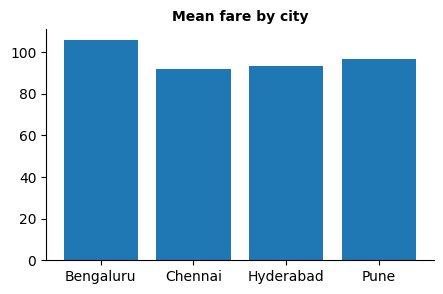

question 1 -> success after 2 attempt(s)
question 2 -> ASK THE USER after 3 attempt(s)


In [ ]:
def generate_execute_repair(question, df, llm, max_tries=3):
    prompt = build_prompt(question, df)
    for attempt in range(1, max_tries + 1):
        code_str = llm(prompt)
        err = execute(code_str, df)
        if err is None:
            plt.show()
            return (code_str, attempt)
        else:
            plt.close("all")
            prompt = build_repair_prompt(question, df, err)
    return (None, max_tries)

code_ok, tries_ok = generate_execute_repair("average fare by city", df, fake_llm)
code_bad, tries_bad = generate_execute_repair("average customer happiness by city", df, fake_llm)
print("question 1 ->", "success" if code_ok else "failed", "after", tries_ok, "attempt(s)")
print("question 2 ->", "success" if code_bad else "ASK THE USER", "after", tries_bad, "attempt(s)")

assert code_ok is not None and tries_ok == 2, "the typo should be repaired on the second attempt"
assert code_bad is None and tries_bad == 3, "an invented column cannot be repaired: ask the user after 3 tries"

---
## Case 4 · Specs, not just code (Vega-Lite specs, validation, evaluation)
ChatViz can also return a **chart specification** (a Vega-Lite-style dictionary). The question was **"average fare by vehicle type in 2025, as a bar chart"**.
Four candidate specs came back from the LLM; one is correct.

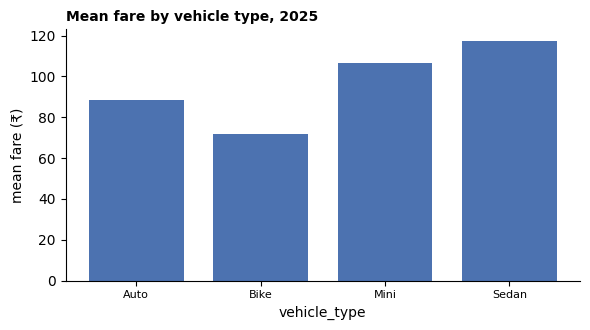

In [ ]:
intent = {"aggregate": "mean", "filters": {"year": [2025]}}

good = {"title": "Mean fare by vehicle type, 2025", "transform": [{"filter": {"field": "year", "equal": 2025}}], "mark": "bar",
        "encoding": {"x": {"field": "vehicle_type", "type": "nominal"},
                     "y": {"field": "fare", "aggregate": "mean", "type": "quantitative", "title": "mean fare (₹)"}}}

import copy as _copy
B1 = _copy.deepcopy(good); B1["encoding"]["colour"] = {"field": "city", "type": "nominal"}                                     # key typo
B2 = _copy.deepcopy(good); B2["encoding"]["y"]["field"] = "fare_amount"                                                         # invented field
B3 = _copy.deepcopy(good); B3["encoding"]["shape"] = {"field": "wait_min", "type": "quantitative"}                              # wrong channel
B4 = _copy.deepcopy(good); B4["transform"] = []; B4["encoding"]["y"]["aggregate"] = "sum"                                       # wrong aggregate + filter dropped
specs = {"good": good, "B1": B1, "B2": B2, "B3": B3, "B4": B4}
render_spec(good, df); plt.tight_layout(); plt.show()

### 4a · Write two of the four validation checks
The **schema** and **field** checks are written for you. Write the **type–channel** check (shape must not encode a quantitative field; size must not encode a nominal field)
and the **sanity** check (compare the spec with the user's `intent`: aggregation and filters). Each returns a list of problem strings (empty list = pass).

In [ ]:
import difflib
VALID_TOP = {"title", "data", "transform", "mark", "encoding"}
VALID_CH  = {"x", "y", "color", "shape", "size"}
VALID_KEYS = {"field", "type", "aggregate", "sort", "scale", "title", "condition", "value", "bin"}

def check_schema(spec):
    out = [f"unknown key '{k}'" for k in spec if k not in VALID_TOP]
    for ch, e in spec["encoding"].items():
        if ch not in VALID_CH:
            m = difflib.get_close_matches(ch, VALID_CH, 1)
            out.append(f"unknown channel '{ch}'" + (f" (did you mean '{m[0]}'?)" if m else ""))
    return out

def check_field(spec, df):
    used = [e["field"] for e in spec["encoding"].values() if isinstance(e, dict) and "field" in e]
    used += [t["filter"]["field"] for t in spec.get("transform", []) if "filter" in t]
    return [f"field '{f}' is not in the dataset" for f in used if f not in df.columns]

In [ ]:
def check_type_channel(spec):
    problems = []
    for ch, e in spec.get("encoding", {}).items():
        if not isinstance(e, dict):
            continue
        t = e.get("type")
        if ch == "shape" and t == "quantitative":
            problems.append("shape channel cannot encode quantitative field")
        elif ch == "size" and t == "nominal":
            problems.append("size channel cannot encode nominal field")
    return problems

def check_sanity(spec, intent):
    problems = []
    # Check aggregate
    found_agg = None
    for ch in ["x", "y"]:
        e = spec.get("encoding", {}).get(ch, {})
        if isinstance(e, dict) and "aggregate" in e:
            found_agg = e["aggregate"]
    if found_agg != intent.get("aggregate"):
        problems.append(f"aggregate does not match user intent: found {found_agg}, expected {intent.get('aggregate')}")

    # Check filters
    transforms = spec.get("transform", [])
    filter_fields = [t["filter"]["field"] for t in transforms if isinstance(t, dict) and "filter" in t and "field" in t["filter"]]
    for f, val in intent.get("filters", {}).items():
        if f not in filter_fields:
            problems.append(f"missing transform filter on field '{f}'")
        else:
            # verify values are equal
            matching_filter = [t["filter"] for t in transforms if isinstance(t, dict) and "filter" in t and t["filter"].get("field") == f][0]
            expected_val = val[0] if isinstance(val, list) and len(val) == 1 else val
            actual_val = matching_filter.get("equal")
            if actual_val != expected_val:
                problems.append(f"filter on field '{f}' does not match expected value")
    return problems

def validate(spec, df, intent):
    return {"1 schema": check_schema(spec), "2 field": check_field(spec, df),
            "3 type-channel": check_type_channel(spec), "4 sanity": check_sanity(spec, intent)}

report = pd.DataFrame({name: {k: ("pass" if not v else "; ".join(v)) for k, v in validate(sp, df, intent).items()} for name, sp in specs.items()}).T
display(report)

assert check_type_channel(good) == [] and len(check_type_channel(B3)) == 1
assert check_sanity(good, intent) == [] and len(check_sanity(B4, intent)) >= 2
assert check_type_channel(B1) == [] and check_sanity(B2, intent) == [], "each bad spec should be stopped by ITS check"

,1 schema,2 field,3 type-channel,4 sanity
good,pass,pass,pass,pass
B1,unknown channel 'colour' (did you mean 'color'?),pass,pass,pass
B2,pass,field 'fare_amount' is not in the dataset,pass,pass
B3,pass,pass,shape channel cannot encode quantitative field,pass
B4,pass,pass,pass,"aggregate does not match user intent: found sum, expected mean; missing transform filt..."


### 4b · Evaluate ChatViz on a benchmark
ChatViz was tested on 6 benchmark queries. The table records which **components** of its output matched the reference spec and whether the **plotted values** were right.
Compute: `exact_match` per query (all five components correct), the **exact-match rate**, the **execution accuracy** (values right), the **component accuracies**, and the list of queries that count for execution accuracy but **not** for exact match.

### Reflection: specifications and evaluation

10. Why should ChatViz validate a generated chart specification before executing it? Identify two checks that would improve reliability.

    Validating a chart specification before execution ensures that errors are caught prior to rendering, preventing confusing syntax errors or runtime crashes from reaching the user. Two critical validation checks that improve reliability are field existence checks (verifying that all referenced fields exist in the database schema) and type-channel compatibility checks (ensuring quantitative variables are not assigned to nominal-only channels like shape, and vice versa).

11. What evidence would convince you that ChatViz is ready for wider deployment? Propose three evaluation criteria, including at least one about correctness and one about user experience.

    To prove deployment readiness, I would require: (1) Execution Correctness where at least 95% of generated charts plot the mathematically correct data subsets; (2) Visual Safety where 99% of charts pass design-rule constraints (no truncated y-axes or unlabelled charts); and (3) User Recovery Success showing that analysts can resolve multi-turn ambiguities within a single natural language turn using interactive interface overrides.

In [ ]:
T, F = True, False
ev = pd.DataFrame({"chart":        [T, T, F, T, T, F],
                   "x":            [T, T, T, T, T, T],
                   "y":            [T, T, T, T, T, T],
                   "aggregation":  [T, F, T, T, T, T],
                   "filter":       [T, T, T, F, T, T],
                   "values_right": [T, F, T, F, T, T]}, index=["Q1", "Q2", "Q3", "Q4", "Q5", "Q6"])
COMPONENTS = ["chart", "x", "y", "aggregation", "filter"]
ev

,chart,x,y,aggregation,filter,values_right
Q1,True,True,True,True,True,True
Q2,True,True,True,False,True,False
Q3,False,True,True,True,True,True
Q4,True,True,True,True,False,False
Q5,True,True,True,True,True,True
Q6,False,True,True,True,True,True


In [ ]:
ev["exact_match"] = ev[COMPONENTS].all(axis=1)

exact_match_rate   = ev["exact_match"].mean()
execution_accuracy = ev["values_right"].mean()
component_acc      = ev[COMPONENTS].mean().to_dict()
ea_not_em          = list(ev[ev["values_right"] & ~ev["exact_match"]].index)

print(exact_match_rate, execution_accuracy, component_acc, ea_not_em)

# Quick validation checks
assert abs(exact_match_rate - 2/6) < 1e-4
assert abs(execution_accuracy - 4/6) < 1e-4
assert component_acc["x"] == 1.0
assert ea_not_em == ["Q3", "Q6"]

0.3333333333333333 0.6666666666666666 {'chart': 0.6666666666666666, 'x': 1.0, 'y': 1.0, 'aggregation': 0.8333333333333334, 'filter': 0.8333333333333334} ['Q3', 'Q6']


---
## Case 5 · Editing the chart by talking to it (conversational chart editing, salience, titles)
An analyst asks ChatViz for *mean fare by city* and then edits it with four utterances. Each edit must be a **minimal patch** to the spec.

In [ ]:
base = {"title": "Mean fare by city", "transform": [], "mark": "bar",
        "encoding": {"x": {"field": "city", "type": "nominal"},
                     "y": {"field": "fare", "aggregate": "mean", "type": "quantitative", "title": "mean fare (₹)"}}}
g = df.groupby("city")["fare"].mean()
focus_city = g.idxmax()
print("focus city:", focus_city, "| mean fare ₹%.0f vs ₹%.0f for the other cities on average" % (g.max(), g.drop(focus_city).mean()))

focus city: Bengaluru | mean fare ₹106 vs ₹94 for the other cities on average


### 5a · Four edits
Write the patches (start from a **deep copy** so `base` is never modified):
1. *"sort highest first"* → set `sort` to `"-y"` on the **x** encoding
2. *"make the bars horizontal"* → swap the `x` and `y` encodings
3. *"highlight the focus city in orange"* → set `encoding["color"]` to `{"condition": {"field": "city", "equal": focus_city, "value": ACCENT}, "value": GREY}`
4. *"add a title that says the point"* → a title that **asserts** the point and **names the focus city** (not "This chart shows …")

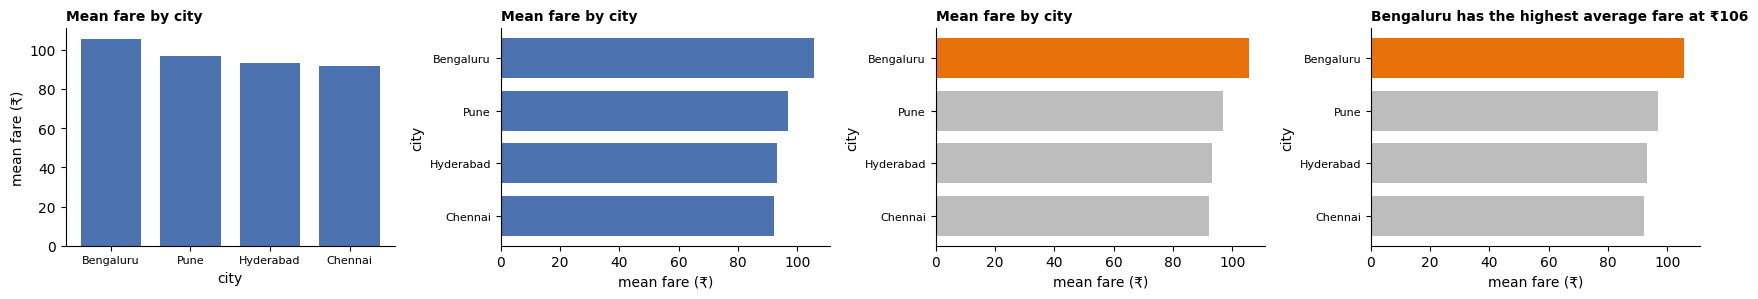

In [ ]:
import copy

spec1 = copy.deepcopy(base)
# Edit 1: sort highest first
spec1["encoding"]["x"]["sort"] = "-y"

spec2 = copy.deepcopy(spec1)
# Edit 2: swap x and y to make the bars horizontal
spec2["encoding"]["x"], spec2["encoding"]["y"] = spec1["encoding"]["y"], spec1["encoding"]["x"]

spec3 = copy.deepcopy(spec2)
# Edit 3: highlight focus_city in orange
spec3["encoding"]["color"] = {
    "condition": {"field": "city", "equal": focus_city, "value": ACCENT},
    "value": GREY
}

spec4 = copy.deepcopy(spec3)
# Edit 4: assertion title naming the focus city
spec4["title"] = f"Bengaluru has the highest average fare at ₹{g[focus_city]:.0f}"

show_specs([spec1, spec2, spec3, spec4], df, ncols=4, w=4.3, h=3.1)

assert spec_diff(base, spec1) == ["encoding.x.sort"], "edit 1 must change only the sort"
assert spec_diff(spec1, spec2) != [] and spec2["encoding"]["x"]["field"] == "fare", "edit 2: x and y must be swapped"
assert spec_diff(spec2, spec3) and all(p.startswith("encoding.color") for p in spec_diff(spec2, spec3)), "edit 3 must only add the colour encoding"
assert spec_diff(spec3, spec4) == ["title"], "edit 4 must change only the title"
assert focus_city in spec4["title"] and lint_chart(spec4) == ["OK"], f"title problems: {lint_chart(spec4)}"

### 5b · Make the answer pop out
A second question: *"Which city has the lowest cancellation rate?"* ChatViz answers with a rainbow-coloured bar chart and no annotation.
Write `bar_colors(labels, answer)` so that **only the answer bar** gets the accent colour and every other bar is grey, and write a one-line **annotation** that states the answer in words.

### Reflection: conversational chart editing

12. Compare making a chart change through natural language with changing it through a traditional visual interface. What are the main benefits and risks of the conversational approach?

    Benefits: Conversational modification lowers the barrier to entry, allowing non-technical users to quickly state intent without searching through complex menus, and maintains a chronological history of changes.
    
    Risks: It introduces semantic ambiguity and potential interpreter errors, requiring users to carefully verify whether the system's changes match their intended criteria, whereas visual UI controls provide direct manipulation with predictable, instant feedback.

13. If the user asks to "make it clearer," what additional information should ChatViz request before changing the chart? Suggest at least two possible interpretations.

    ChatViz should ask whether the user intends to improve visual readability or refine the data representation. Two possible interpretations include: (1) Visual Layout Adjustment, such as sorting bars in descending order or rotating labels to prevent overlap, and (2) Data Aggregation/Filtering, such as narrowing down to top categories or switching from absolute counts to percentages to show proportions more clearly.

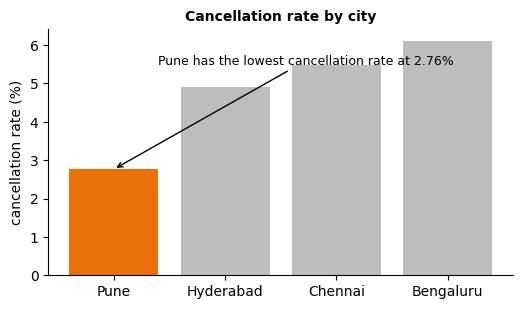

In [ ]:
rate = df.groupby("city")["cancelled"].mean().sort_values() * 100
answer = rate.index[0]

def bar_colors(labels, answer):
    return [ACCENT if l == answer else GREY for l in labels]

annotation = f"{answer} has the lowest cancellation rate at {rate.iloc[0]:.2f}%"

colors = bar_colors(list(rate.index), answer)
assert colors.count(ACCENT) == 1 and colors.count(GREY) == len(rate) - 1
assert answer in annotation, "name the answer city in the annotation"

fig, ax = plt.subplots(figsize=(6, 3.2))
ax.bar(rate.index, rate.values, color=colors)
ax.annotate(annotation, xy=(0, rate.iloc[0]), xytext=(0.4, rate.max() * 0.9), arrowprops=dict(arrowstyle="->"), fontsize=9)
ax.set_ylabel("cancellation rate (%)"); ax.set_title("Cancellation rate by city")
plt.show()

---
## Case 6 · Post-mortem: what went wrong in the pilot? (benefits, failure modes, the nested model, mitigations)
Six incidents were reported during the pilot.

| # | Incident |
|---|---|
| I1 | The manager asked for *average* fare per city. The chart's title says "Average", but the bars are **totals**, so Bengaluru (most rides) wins. |
| I2 | After *"only 2025"*, the follow-up *"what about cancellations?"* was drawn for **all years**, with no warning. |
| I3 | A chart was drawn of `driver_score`, a column that **does not exist**; the tool quietly filled it with random numbers. |
| I4 | A **line** was drawn connecting Auto, Mini, Sedan and Bike for *"compare average fare by vehicle type"*. |
| I5 | Bars comparing cancellation rates of 4.1 % and 4.4 % started the y-axis at 4 %, making one city look **twice as bad**. |
| I6 | The caption under a scatter plot read *"Surge pricing **causes** cancellations."* |

### Reflection: rollout priorities and safeguards

14. What safeguards are needed when a visualization could expose sensitive operational information, such as driver performance or neighborhood-level demand?

    To safeguard sensitive operational data, ChatViz should implement strict, role-based database views and row-level access controls so analysts can only query aggregates within their authorized scope. Additionally, the system should enforce k-anonymity limits (like refusing to plot demand coordinates or driver stats when the underlying sample size is below a certain threshold) to prevent the accidental exposure or reverse-engineering of individual driver identities and granular neighborhood patterns.

15. After auditing ChatViz, what is the single most important improvement you would prioritize, and why?

    The single most important improvement to prioritize is implementing a robust schema-validation and semantic intent-checking filter before any code or chart specification is rendered. This addresses the most dangerous and costly failures—such as plotting a sum instead of an average or generating charts using non-existent fields—by catching alignment errors early at the abstraction layer, ensuring the system never presents a visually correct but analytically misleading chart to decision-makers.

### 6a · Classify
**(i)** Label each incident with exactly one failure mode from `FAILURE_MODES`.
**(ii)** Place each statement in the right level of **Munzner's nested model** (`"domain"`, `"abstraction"`, `"idiom"`, `"algorithm"`).
**(iii)** Pick the best **mitigation** for each situation from `MITIGATIONS`.

* **L1.** The code crashes with a `KeyError`.
* **L2.** The tool answers a *trend* question when the analyst actually needed to *compare two groups*.
* **L3.** A 12-slice pie is used to compare ride counts.
* **L4.** Finance defines "revenue" net of driver incentives, but the tool uses gross fares.

Mitigation situations: **M1** — follow-ups silently drop filters (I2). **M2** — the tool keeps choosing pies and truncated axes (I4/I5). **M3** — a wrong aggregation slips through while the chart runs fine (I1). **M4** — a chart is about to go into the **board report**.

In [ ]:
FAILURE_MODES = ["hallucinated field", "wrong aggregation / filter", "wrong chart for the task", "misleading design", "context drift", "over-confident narrative"]
LEVELS = ["domain", "abstraction", "idiom", "algorithm"]
MITIGATIONS = ["echo the interpretation", "make choices editable", "validate before showing", "keep the spec / code", "constrain the design", "human review for decisions"]

In [ ]:
failure_mode = {
    "I1": "wrong aggregation / filter",
    "I2": "context drift",
    "I3": "hallucinated field",
    "I4": "wrong chart for the task",
    "I5": "misleading design",
    "I6": "over-confident narrative",
}
nested_level = {
    "L1": "algorithm",
    "L2": "abstraction",
    "L3": "idiom",
    "L4": "domain",
}
mitigation = {
    "M1": "echo the interpretation",
    "M2": "constrain the design",
    "M3": "validate before showing",
    "M4": "human review for decisions",
}

assert all(v in FAILURE_MODES for v in failure_mode.values()), "failure_mode: choose from FAILURE_MODES"
assert all(v in LEVELS for v in nested_level.values()), "nested_level: choose from LEVELS"
assert all(v in MITIGATIONS for v in mitigation.values()), "mitigation: choose from MITIGATIONS"

### 6b · Your recommendation
Incident I1 looked perfectly fine on screen and was only noticed because a manager happened to check the numbers. In two or three sentences: which level of the nested model do the costliest errors live at, why are they dangerous, and what should SwiftBite-style rollout rules require before ChatViz goes to every analyst? (Use RideNow in your answer.)

### Reflection: rollout priorities and safeguards

14. What safeguards are needed when a visualization could expose sensitive operational information, such as driver performance or neighborhood-level demand?

    * To safeguard sensitive operational data, ChatViz should implement strict, role-based database views and row-level access controls so analysts can only query aggregates within their authorized scope. Additionally, the system should enforce k-anonymity limits (e.g., refusing to plot demand coordinates or driver stats when the underlying sample size is below a certain threshold) to prevent the accidental exposure or reverse-engineering of individual driver identities and granular neighborhood patterns.

15. After auditing ChatViz, what is the single most important improvement you would prioritize, and why?

    * The single most important improvement to prioritize is implementing a robust schema-validation and semantic intent-checking filter before any code or chart specification is rendered. This addresses the most dangerous and costly failures—such as plotting a sum instead of an average (I1) or generating charts using non-existent fields (I3)—by catching alignment errors early at the abstraction layer, ensuring the system never presents a visually correct but analytically misleading chart to decision-makers.

In [ ]:
final_recommendation = """The costliest and most dangerous errors live at the Abstraction level. These are dangerous because the charts look syntactically correct and render without crashing, but they answer the wrong business question (e.g., displaying sum instead of mean). To prevent these errors at RideNow, rollout rules must require echoing semantic interpretations back to the analyst, running automated schema validations, and mandating human review with a data-verification sandbox before charts are published to senior leadership."""

---
### Before you finish
Run the cell below to see whether any answer has been left blank.

In [ ]:
_required = ["abstract_tasks", "ambiguity_strategy", "turn_types", "transitions", "session_6_turns", "session_6_better", "turns_below_half",
             "prompt_fix", "exact_match_rate", "execution_accuracy", "component_acc", "ea_not_em", "annotation",
             "failure_mode", "nested_level", "mitigation", "final_recommendation"]
_blank = []
for _name in _required:
    _v = globals().get(_name)
    if _v is None or (isinstance(_v, str) and not _v.strip()) or (isinstance(_v, dict) and any(x is None for x in _v.values())):
        _blank.append(_name)
print("All answers filled in." if not _blank else "Still blank: " + ", ".join(_blank))

All answers filled in.
